In [3]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.3f}'.format)

In [4]:
from google.colab import files

uploaded = files.upload()

Saving column_3C.dat to column_3C.dat


In [5]:
columns = [
    'pelvic_incidence',
    'pelvic_tilt',
    'lumbar_lordosis_angle',
    'sacral_slope',
    'pelvic_radius',
    'degree_spondylolisthesis',
    'class'
]

df = pd.read_csv(
    'column_3C.dat',
    sep=r'\s+',
    header=None,
    names=columns
)

df.head()

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
0,63.030,22.550,39.610,40.480,98.670,-0.250,DH
1,39.060,10.060,25.020,29.000,114.410,4.560,DH
2,68.830,22.220,50.090,46.610,105.990,-3.530,DH
3,69.300,24.650,44.310,44.640,101.870,11.210,DH
4,49.710,9.650,28.320,40.060,108.170,7.920,DH


In [6]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (310, 7)

Column Names:
['pelvic_incidence', 'pelvic_tilt', 'lumbar_lordosis_angle', 'sacral_slope', 'pelvic_radius', 'degree_spondylolisthesis', 'class']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 310 entries, 0 to 309
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   pelvic_incidence          310 non-null    float64
 1   pelvic_tilt               310 non-null    float64
 2   lumbar_lordosis_angle     310 non-null    float64
 3   sacral_slope              310 non-null    float64
 4   pelvic_radius             310 non-null    float64
 5   degree_spondylolisthesis  310 non-null    float64
 6   class                     310 non-null    object 
dtypes: float64(6), object(1)
memory usage: 17.1+ KB


In [7]:
# mean, median, SD

numeric_features = df.select_dtypes(include=np.number).columns

summary_statistics = pd.DataFrame({
    'Mean': df[numeric_features].mean(),
    'Median': df[numeric_features].median(),
    'Standard Deviation': df[numeric_features].std(),
    'Minimum': df[numeric_features].min(),
    'Maximum': df[numeric_features].max()
})

display(summary_statistics)

,Mean,Median,Standard Deviation,Minimum,Maximum
pelvic_incidence,60.496,58.690,17.236,26.150,129.830
pelvic_tilt,17.543,16.360,10.008,-6.550,49.430
lumbar_lordosis_angle,51.931,49.565,18.554,14.000,125.740
sacral_slope,42.954,42.405,13.423,13.370,121.430
pelvic_radius,117.921,118.265,13.318,70.080,163.070
degree_spondylolisthesis,26.297,11.765,37.559,-11.060,418.540


In [8]:
# checking missing values

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
pelvic_incidence            0
pelvic_tilt                 0
lumbar_lordosis_angle       0
sacral_slope                0
pelvic_radius               0
degree_spondylolisthesis    0
class                       0
dtype: int64

Total missing values: 0


In [9]:
# checking duplicates

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [10]:
# outlier detection

outlier_summary = {}

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_summary[col] = len(outliers)

outlier_summary = pd.Series(outlier_summary)

print("Number of outliers per feature:")
display(outlier_summary)

Number of outliers per feature:


,0
pelvic_incidence,3
pelvic_tilt,13
lumbar_lordosis_angle,1
sacral_slope,1
pelvic_radius,11
degree_spondylolisthesis,10


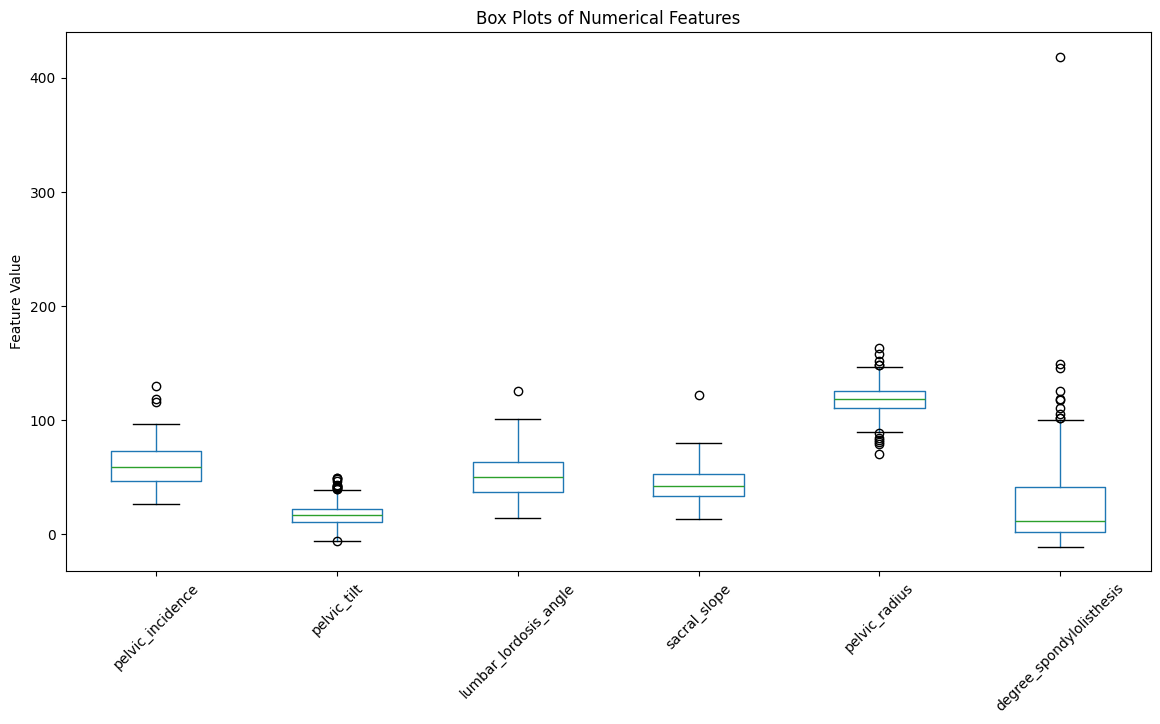

In [11]:
plt.figure(figsize=(14, 7))

df[numeric_features].boxplot()

plt.title("Box Plots of Numerical Features")
plt.ylabel("Feature Value")
plt.xticks(rotation=45)
plt.grid(False)

plt.show()

In [12]:
# handling outliers

df_clean = df.copy()

for col in numeric_features:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_clean[col] = df_clean[col].clip(
        lower_bound,
        upper_bound
    )

print("Outliers handled using IQR-based clipping.")

Outliers handled using IQR-based clipping.


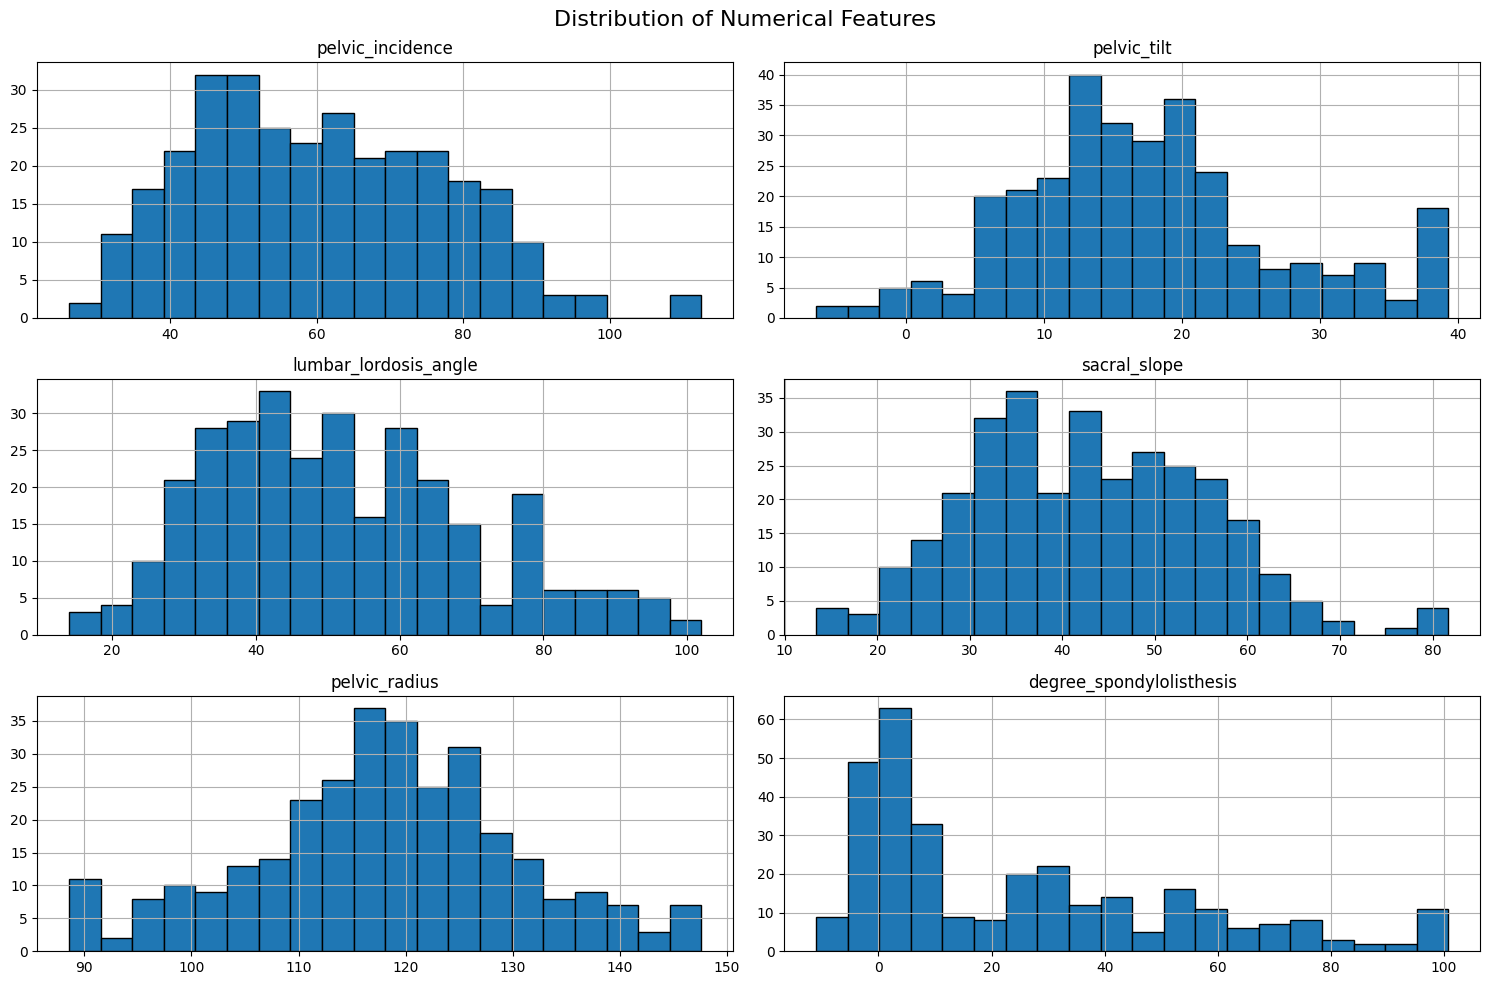

In [13]:
# data visualization

df_clean[numeric_features].hist(
    figsize=(15, 10),
    bins=20,
    edgecolor='black'
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)

plt.tight_layout()
plt.show()

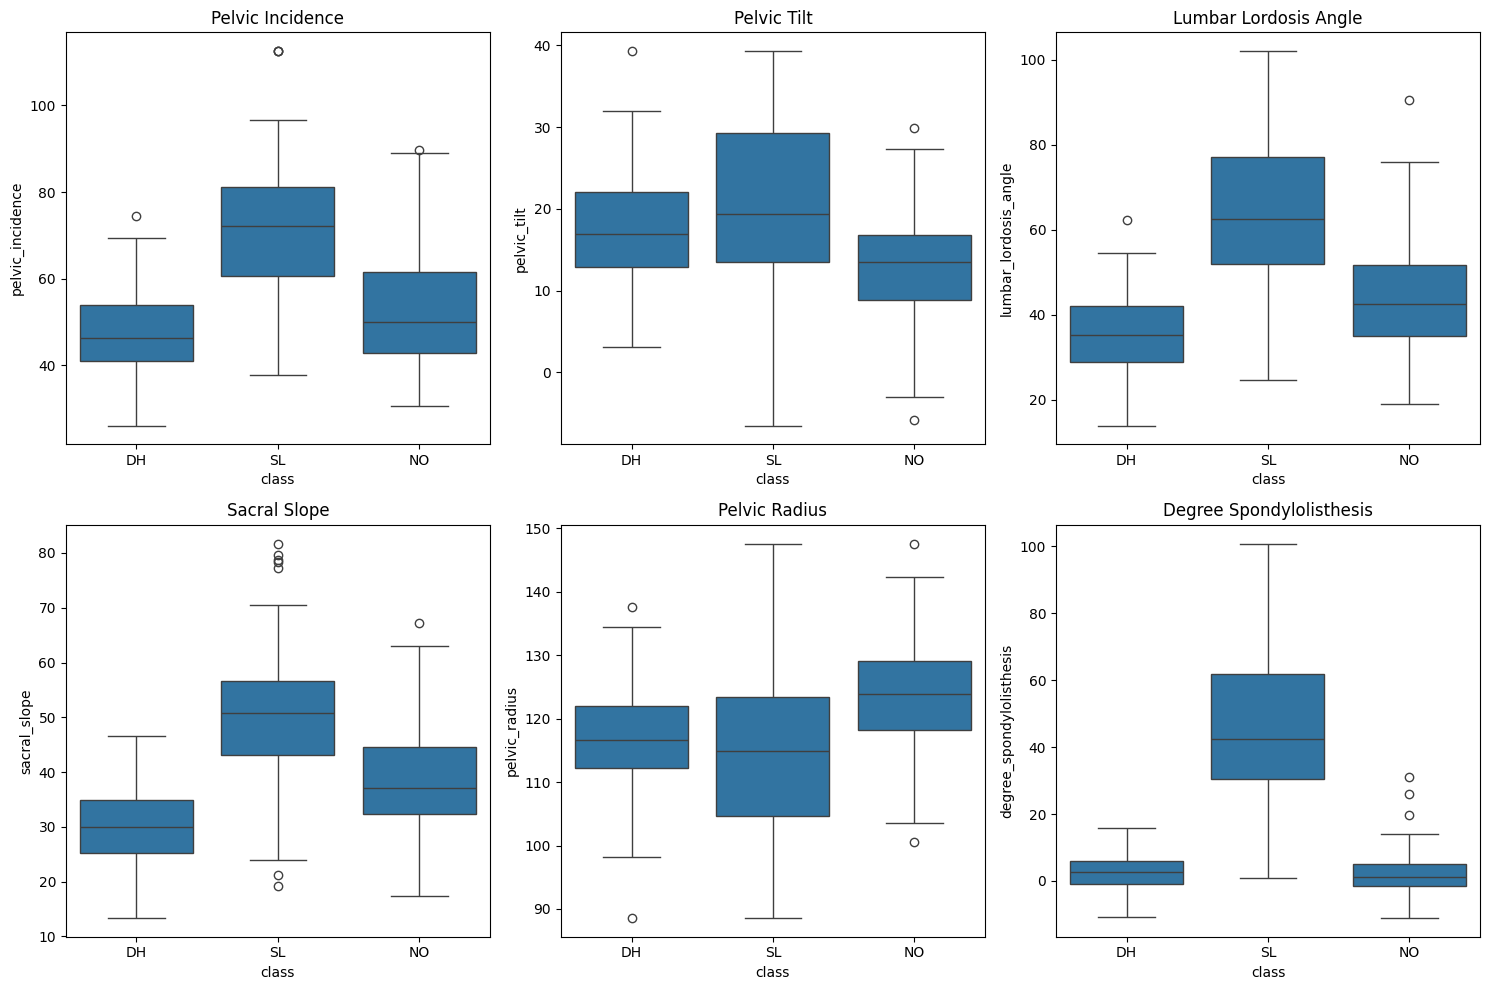

In [14]:
# box plots by class

plt.figure(figsize=(15, 10))

for i, feature in enumerate(numeric_features, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(
        data=df_clean,
        x='class',
        y=feature
    )

    plt.title(feature.replace('_', ' ').title())

plt.tight_layout()
plt.show()

In [15]:
# class distribution

class_counts = df_clean['class'].value_counts()

print("Class distribution:")
print(class_counts)

Class distribution:
class
SL    150
NO    100
DH     60
Name: count, dtype: int64


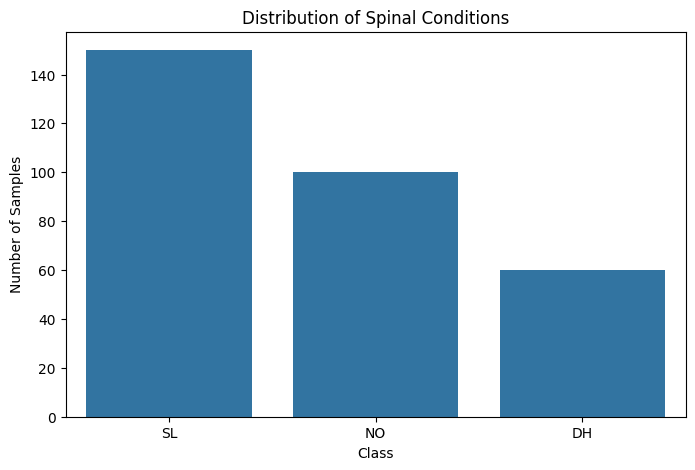

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='class',
    order=df_clean['class'].value_counts().index
)

plt.title("Distribution of Spinal Conditions")
plt.xlabel("Class")
plt.ylabel("Number of Samples")

plt.show()

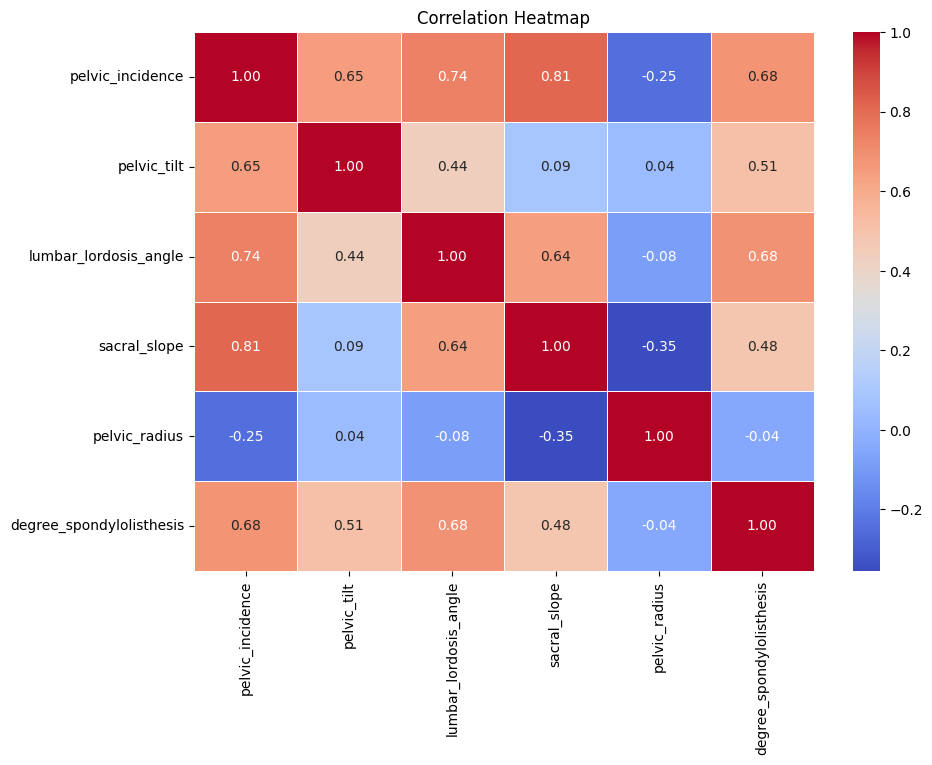

In [18]:
# correlation matrix

plt.figure(figsize=(10, 7))

correlation_matrix = df_clean[numeric_features].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.show()


In [19]:
# data preprocessing

# encoding target variables

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df_clean['class_encoded'] = label_encoder.fit_transform(
    df_clean['class']
)

print("Class Encoding:")
for original, encoded in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(original, "->", encoded)

Class Encoding:
DH -> 0
NO -> 1
SL -> 2


In [20]:
# separating features and targets

X = df_clean[numeric_features]

y = df_clean['class_encoded']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (310, 6)
Target shape: (310,)


In [21]:
# train-test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 248
Testing samples: 62


In [22]:
# class distribution after splitting

print("Training class distribution:")
print(pd.Series(y_train).value_counts())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts())

Training class distribution:
class_encoded
2    120
1     80
0     48
Name: count, dtype: int64

Testing class distribution:
class_encoded
2    30
1    20
0    12
Name: count, dtype: int64


In [24]:
# standardizing features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [25]:
# model training

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

In [26]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'SVM': SVC(
        probability=True,
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    )
}

In [27]:
# training created models

trained_models = {}

for name, model in models.items():

    model.fit(
        X_train_scaled,
        y_train
    )

    trained_models[name] = model

    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
KNN trained successfully.
SVM trained successfully.
Random Forest trained successfully.
Gradient Boosting trained successfully.


In [28]:
# generating predictions

predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test_scaled)

    predictions[name] = y_pred

    print(f"{name}: predictions generated.")

Logistic Regression: predictions generated.
KNN: predictions generated.
SVM: predictions generated.
Random Forest: predictions generated.
Gradient Boosting: predictions generated.


In [29]:
# model evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name in trained_models:

    y_pred = predictions[name]

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average='weighted',
        zero_division=0
    )

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        'Model',
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score'
    ]
)

results_df = results_df.sort_values(
    by='F1-Score',
    ascending=False
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1-Score
4,Gradient Boosting,0.871,0.871,0.871,0.871
0,Logistic Regression,0.839,0.841,0.839,0.837
3,Random Forest,0.839,0.838,0.839,0.836
2,SVM,0.823,0.836,0.823,0.827
1,KNN,0.790,0.824,0.790,0.799


In [30]:
# classification report of each class

from sklearn.metrics import classification_report

target_names = label_encoder.classes_

for name in trained_models:

    print("=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=target_names,
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

          DH       0.70      0.58      0.64        12
          NO       0.74      0.85      0.79        20
          SL       0.97      0.93      0.95        30

    accuracy                           0.84        62
   macro avg       0.80      0.79      0.79        62
weighted avg       0.84      0.84      0.84        62

KNN
              precision    recall  f1-score   support

          DH       0.69      0.75      0.72        12
          NO       0.64      0.80      0.71        20
          SL       1.00      0.80      0.89        30

    accuracy                           0.79        62
   macro avg       0.78      0.78      0.77        62
weighted avg       0.82      0.79      0.80        62

SVM
              precision    recall  f1-score   support

          DH       0.75      0.75      0.75        12
          NO       0.70      0.80      0.74        20
          SL       0.96      0.87      0.91    

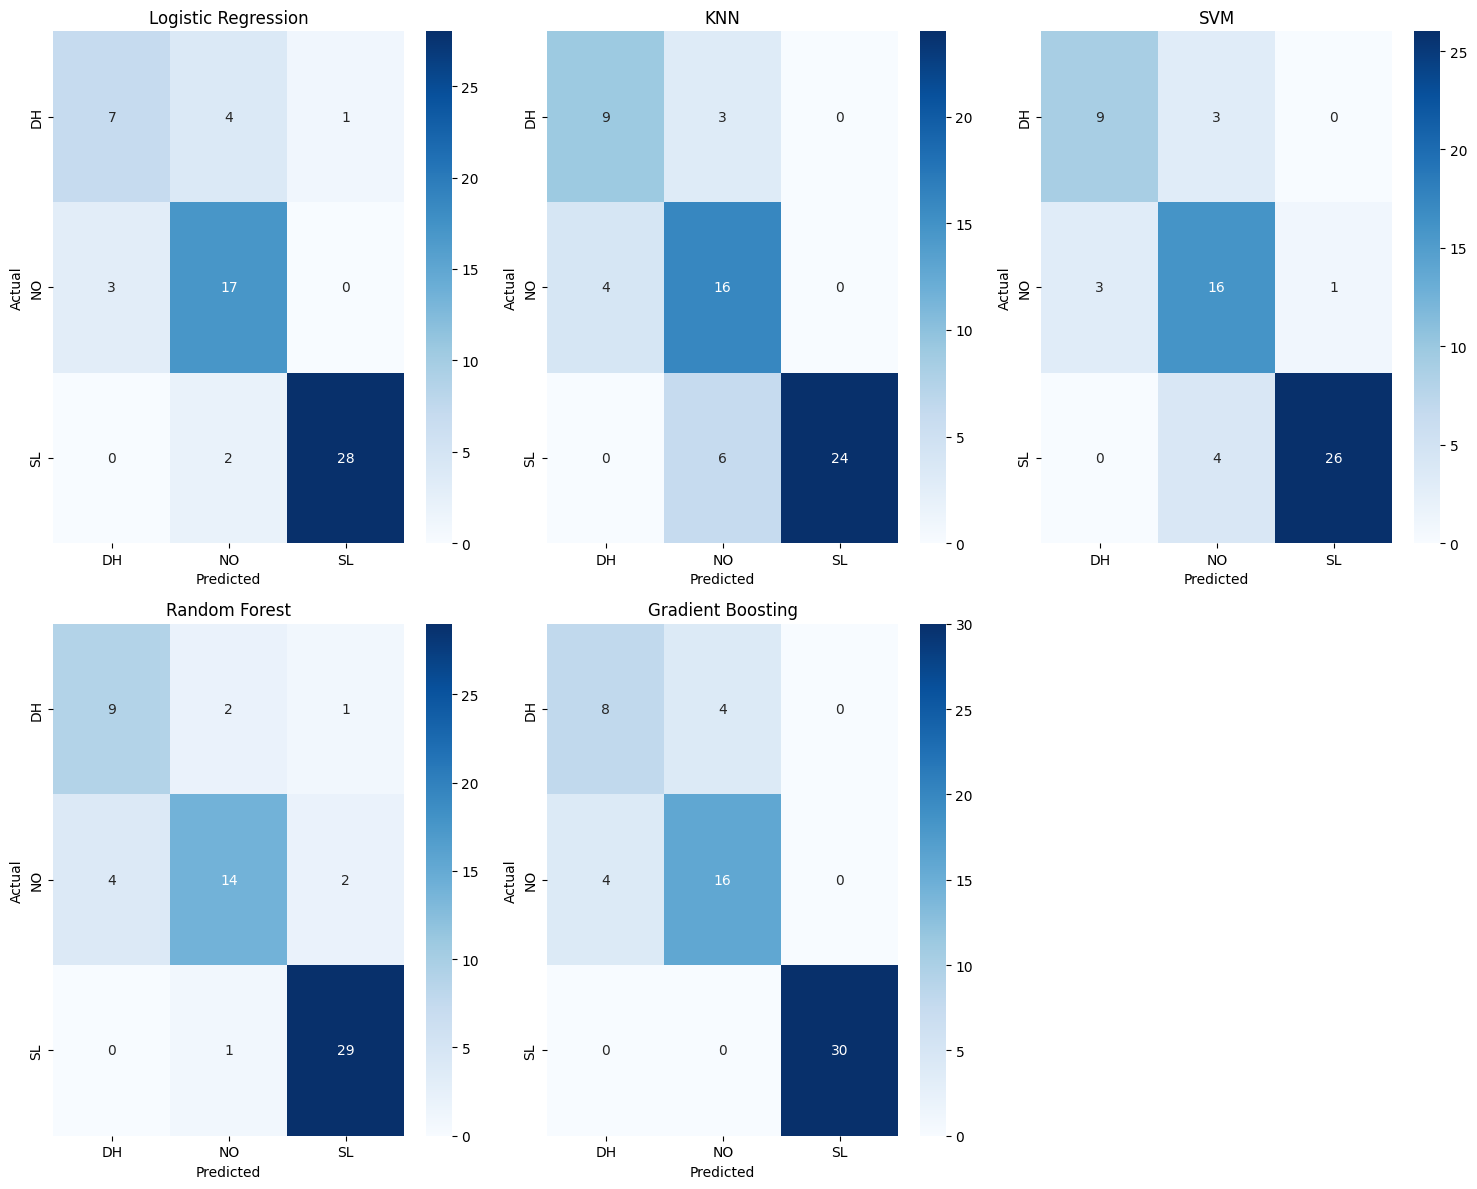

In [31]:
# CM for all models

from sklearn.metrics import confusion_matrix

plt.figure(figsize=(15, 12))

for i, name in enumerate(trained_models, 1):

    cm = confusion_matrix(
        y_test,
        predictions[name]
    )

    plt.subplot(2, 3, i)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=target_names,
        yticklabels=target_names
    )

    plt.title(name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [32]:
# calculating ROC-AUC

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

# Convert target into one-hot / binary representation
y_test_bin = label_binarize(
    y_test,
    classes=np.arange(len(target_names))
)

auc_results = []

for name, model in trained_models.items():

    # Get probability predictions
    y_prob = model.predict_proba(X_test_scaled)

    auc_score = roc_auc_score(
        y_test_bin,
        y_prob,
        multi_class='ovr',
        average='weighted'
    )

    auc_results.append([
        name,
        auc_score
    ])

auc_df = pd.DataFrame(
    auc_results,
    columns=['Model', 'ROC-AUC']
)

auc_df = auc_df.sort_values(
    by='ROC-AUC',
    ascending=False
)

display(auc_df)

,Model,ROC-AUC
0,Logistic Regression,0.961
3,Random Forest,0.960
4,Gradient Boosting,0.960
2,SVM,0.951
1,KNN,0.908


In [33]:
final_results = results_df.merge(
    auc_df,
    on='Model'
)

final_results = final_results.sort_values(
    by='F1-Score',
    ascending=False
)

display(final_results)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,0.871,0.871,0.871,0.871,0.960
1,Logistic Regression,0.839,0.841,0.839,0.837,0.961
2,Random Forest,0.839,0.838,0.839,0.836,0.960
3,SVM,0.823,0.836,0.823,0.827,0.951
4,KNN,0.790,0.824,0.790,0.799,0.908
